# 17 - Paper pages 16-17 beside our estimated charts

Reproduce the **three original chart images** beside our existing results, leaving the different
histories as they stand. Printed page 16 contains Figure 2 (risk prices); page 17 contains Figure 3
(US premiums) and Figure 4 (Finnish premiums). These are PDF pages 18-19 in the supplied file because
of its cover pages. The supplied body is the April 2005 draft associated with the cited paper.

The default **USD / full S4** view matches the broad specification underlying the paper's figures:
world, FX and local risk prices may vary. The gallery also contains our **final FX-only branch**,
with constant world/local prices, and both EUR versions. Every view shows **scalar11 and grouped21**.
The paper itself reports USD investors; its image stays a USD reference when viewing our EUR results.

Keep the frozen 321-month Hungarian dataset, corrected FX means and zero alphas. This is a
**read-only plotting exercise in the existing base kernel**, without fetching or re-estimation.
The original Finnish lines are raster excerpts, not digitized numerical data. Do not sum our two FX
**prices**; premium decompositions instead sum their two **contributions** into one Currency line.

In [1]:
SHOW_SPEC="S4"             # "S4": full structural match; "FX": final FX-only branch
SHOW_PERSPECTIVE="USD"     # "USD" or "EUR"

from pathlib import Path
from io import BytesIO
import hashlib,json,os,sys,importlib.metadata
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display,Image,Markdown
assert SHOW_SPEC in ["S4","FX"] and SHOW_PERSPECTIVE in ["USD","EUR"]
print("Python:",sys.executable)
OUT=ROOT/"output/17_paper_chart_comparison/fixed_2026-11-13"
SOURCE=OUT/"source_figures"
source_manifest=json.loads((SOURCE/"source_manifest.json").read_text())
source_images={}
for figure,info in source_manifest["figures"].items():
    p=SOURCE/info["file"];raw=p.read_bytes();assert hashlib.sha256(raw).hexdigest()==info["sha256"]
    source_images[int(figure)]=plt.imread(BytesIO(raw),format="png")
lock=json.loads((ROOT/"research_synthesis_inputs.json").read_text());used={}
def read(path):
    path=Path(path);relative=path.relative_to(ROOT).as_posix();raw=path.read_bytes()
    if hashlib.sha256(raw).hexdigest()!=lock["files"][relative]:raise ValueError(f"Frozen research input changed: {relative}")
    used[relative]=lock["files"][relative];return raw
data=pd.read_csv(BytesIO(read(ROOT/lock["snapshot"]/"dataset.csv")),index_col=0,float_precision="round_trip")
months=pd.PeriodIndex(data.index,freq="M");dates=months.to_timestamp("M")
assert len(data)==321 and str(months[0])=="2000-01" and str(months[-1])=="2026-09"
ROOTS={spec:ROOT/lock["sources"][str(stage)]["root"] for spec,stage in [("S4",12),("FX",13)]}
models=["scalar11","grouped21"];currencies=["USD","EUR"]
spec_labels={"S4":"Full S4: TV world, FX and HU local","FX":"Final FX-only: constant world and local"}
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.18,"figure.dpi":110})

Python: /Users/lajosgalambos/miniconda3/bin/python


## Derive the plotted series from saved estimates

Reconstruct risk prices from the saved designs and parameter vector. For asset $i$, calculate World,
Currency and Own components as $\lambda_W H_{iW}$, $\lambda_H H_{iH}+\lambda_O H_{iO}$, and
$\lambda_i H_{ii}$. Check that they sum to its saved conditional mean in every month.
No smoothing, interpolation, truncation or annualization is applied. Premium units are monthly log
percentage points. Risk-price plots use the coefficients' own return-unit convention; FX quote/basis
differences make their signs and magnitudes less directly comparable with the paper.

In [2]:
cases={};audit=[]
for spec,root in ROOTS.items():
    manifest=json.loads(read(root/"estimation_manifest.json"));assert manifest["source_dataset_sha256"]==lock["dataset_sha256"]
    for currency in currencies:
        for model in models:
            key=f"{currency}_{model}_{spec}"
            with np.load(BytesIO(read(root/f"parameters_{key}.npz")),allow_pickle=False) as a:p={k:a[k].copy() for k in a.files}
            assert np.array_equal(p["equity_alphas"],np.zeros(3)) and p["H"].shape==(321,5,5)
            z={}
            for name in ["W","H","O","L"]:
                d=pd.read_csv(BytesIO(read(root/f"design_{key}_{name}.csv")),index_col=0,float_precision="round_trip")
                assert pd.PeriodIndex(d.index,freq="M").equals(months);z[name]=d.to_numpy()
            w=5+z["W"].shape[1]-1;h=w+z["H"].shape[1]-1;o=h+z["O"].shape[1]-1
            ix={"W":np.r_[0,np.arange(5,w)],"H":np.r_[3,np.arange(w,h)],"O":np.r_[4,np.arange(h,o)],"L":np.r_[2,np.arange(o,o+z["L"].shape[1]-1)]}
            prices=pd.DataFrame({label:.01*(z[label]@p["theta"][j]) for label,j in ix.items()},index=months)
            prices.columns=["World","HUF FX","Other FX","HU local"];prices["US local"] = .01*p["theta"][1]
            expected=np.einsum("tij,tj->ti",p["H"][:,:,[0,3,4]],prices[["World","HUF FX","Other FX"]].to_numpy())
            expected[:,1]+=prices["US local"]*p["H"][:,1,1];expected[:,2]+=prices["HU local"]*p["H"][:,2,2]
            np.testing.assert_allclose(expected,p["mu"],atol=1e-10,rtol=1e-11)
            premia={}
            for label,i,local in [("US",1,"US local"),("HU",2,"HU local")]:
                H=p["H"];premia[label]=pd.DataFrame({"World":prices["World"]*H[:,i,0],"Currency":prices["HUF FX"]*H[:,i,3]+prices["Other FX"]*H[:,i,4],"Own":prices[local]*H[:,i,i],"Total":p["mu"][:,i]},index=months)
                np.testing.assert_allclose(premia[label][["World","Currency","Own"]].sum(axis=1),premia[label]["Total"],atol=1e-11,rtol=1e-11)
                premia[label].to_csv(OUT/f"premia_{label}_{key}.csv")
            if spec=="FX":assert np.ptp(prices["World"])==np.ptp(prices["HU local"])==0
            cases[(spec,currency,model)]={"prices":prices,"premia":premia}
            prices.to_csv(OUT/f"risk_prices_{key}.csv")
            audit.append({"specification":spec,"perspective":currency,"covariance":model,"months":321,"first":str(months[0]),"last":str(months[-1]),"zero_alphas":True,"max_mean_error":np.abs(expected-p["mu"]).max()})
audit=pd.DataFrame(audit);display(audit)

,specification,perspective,covariance,months,first,last,zero_alphas,max_mean_error
0,S4,USD,scalar11,321,2000-01,2026-09,True,7.105427e-15
1,S4,USD,grouped21,321,2000-01,2026-09,True,2.220446e-15
2,S4,EUR,scalar11,321,2000-01,2026-09,True,1.776357e-15
3,S4,EUR,grouped21,321,2000-01,2026-09,True,1.776357e-15
4,FX,USD,scalar11,321,2000-01,2026-09,True,3.552714e-15
5,FX,USD,grouped21,321,2000-01,2026-09,True,3.552714e-15
6,FX,EUR,scalar11,321,2000-01,2026-09,True,1.776357e-15
7,FX,EUR,grouped21,321,2000-01,2026-09,True,8.881784e-16


## Side-by-side figures and gallery

**Left:** authentic paper chart with its original axes. **Middle/right:** our two covariance models,
with one common scale for all our settings. The original paper axes remain visible, so compare their
tick values when assessing amplitudes. All our observations and extremes remain visible.

The full S4 view is a structural comparison, not a claim that our tests favor every time-varying price.
In the FX-only view, flat world/local prices are imposed restrictions. EUR views keep the paper's USD
chart as a clearly labelled historical reference. Each timeline retains its actual sample dates.

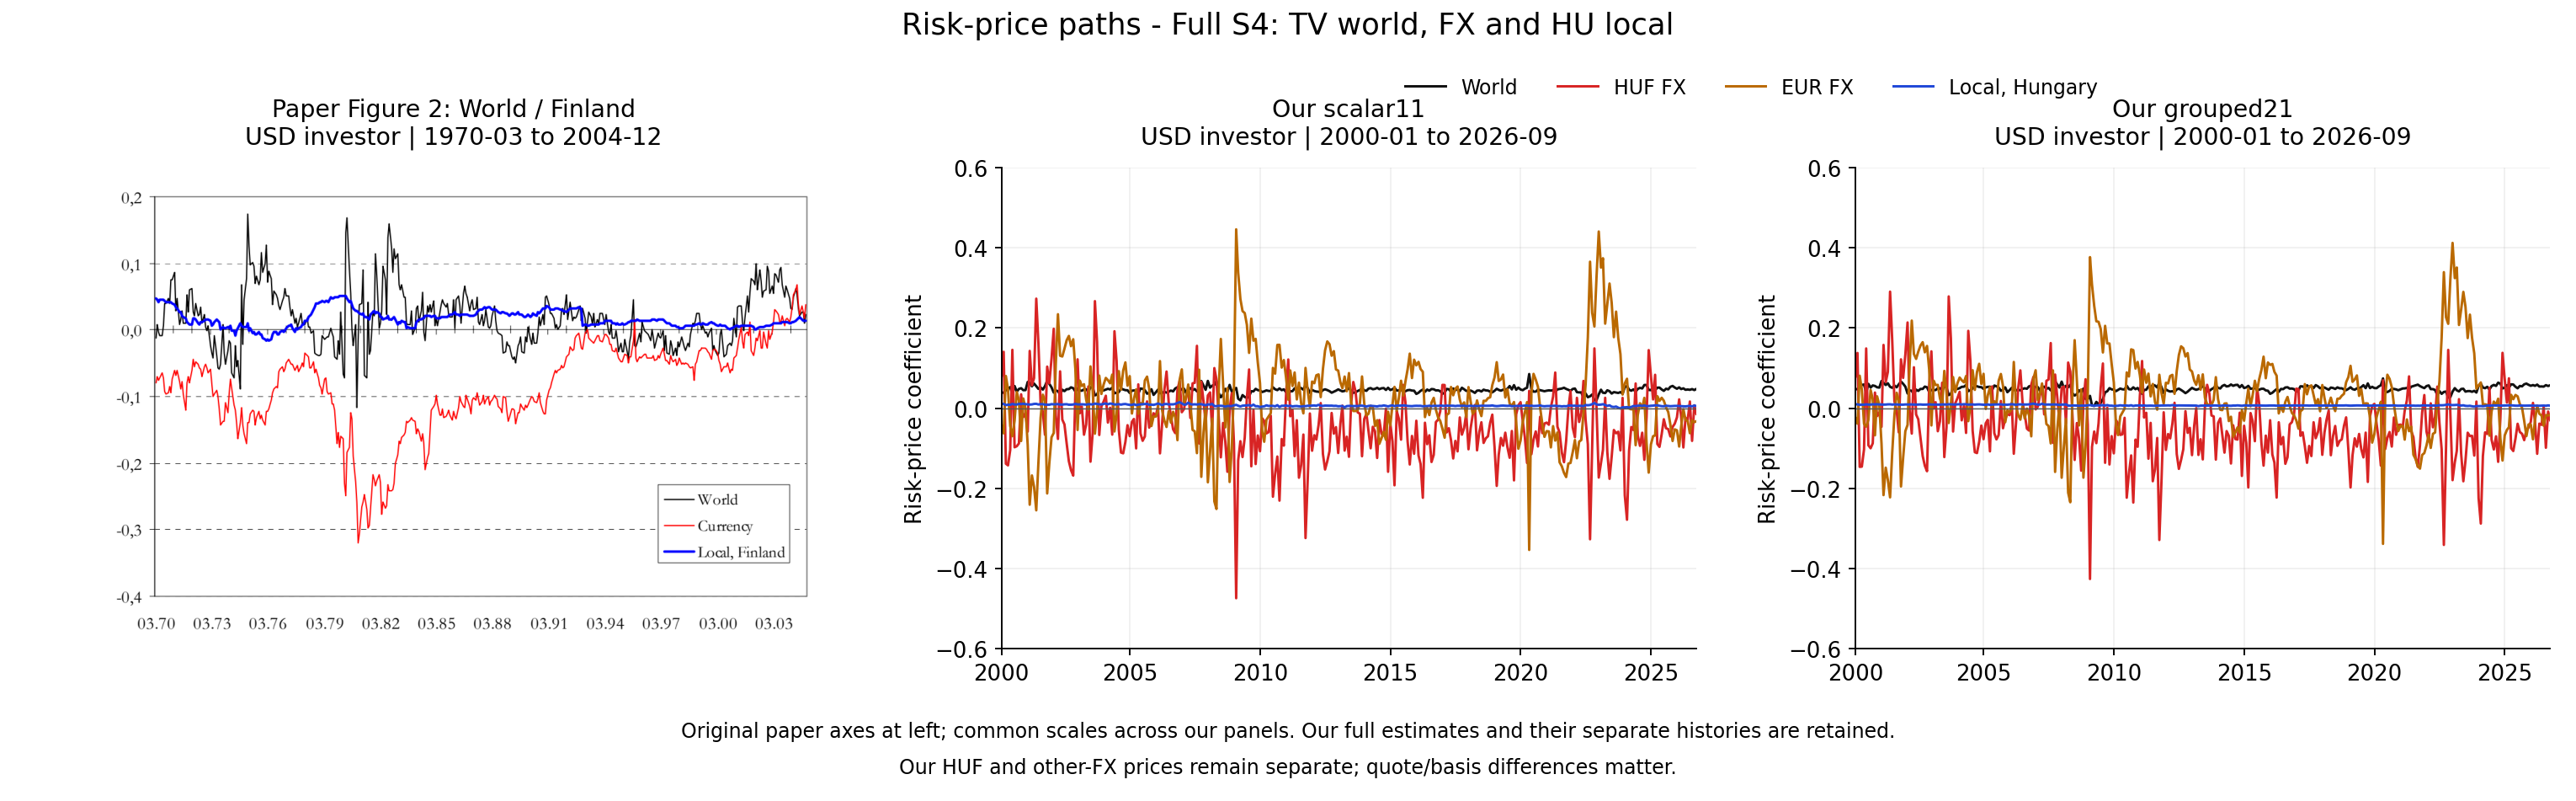

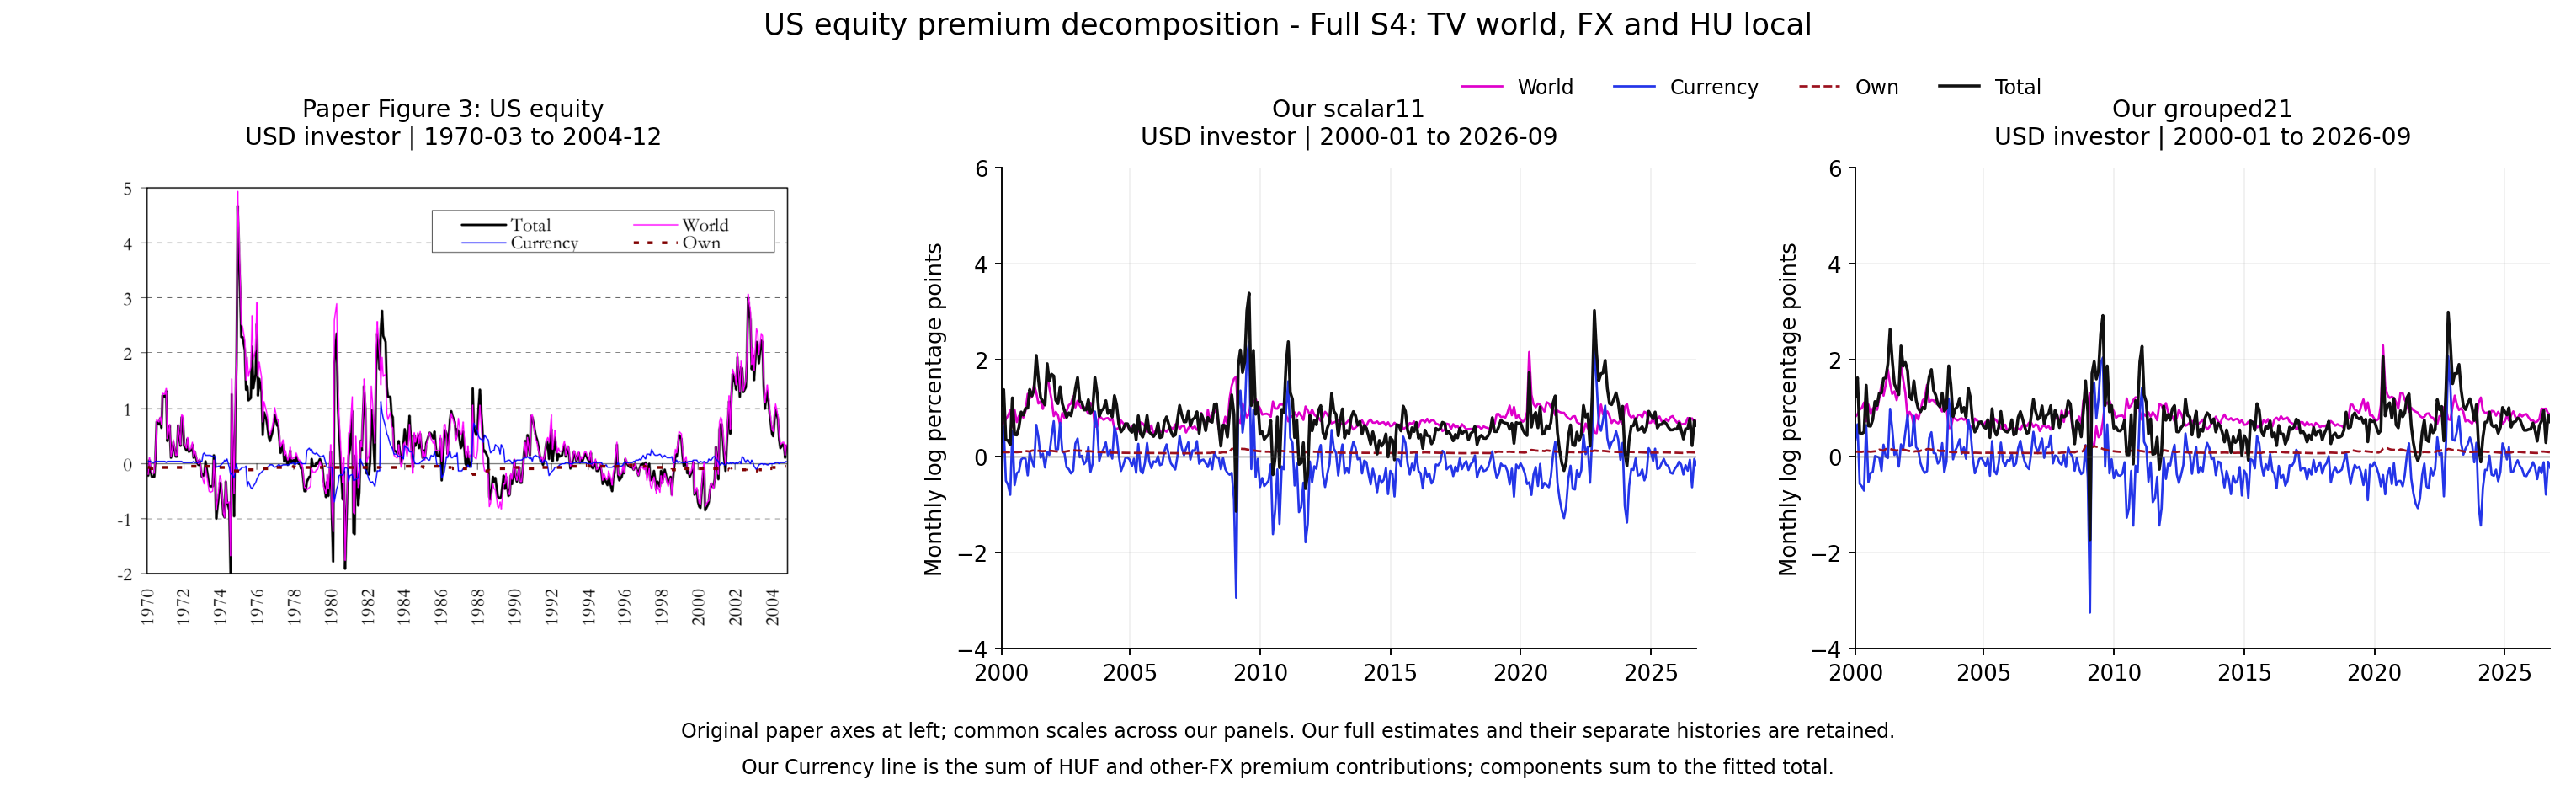

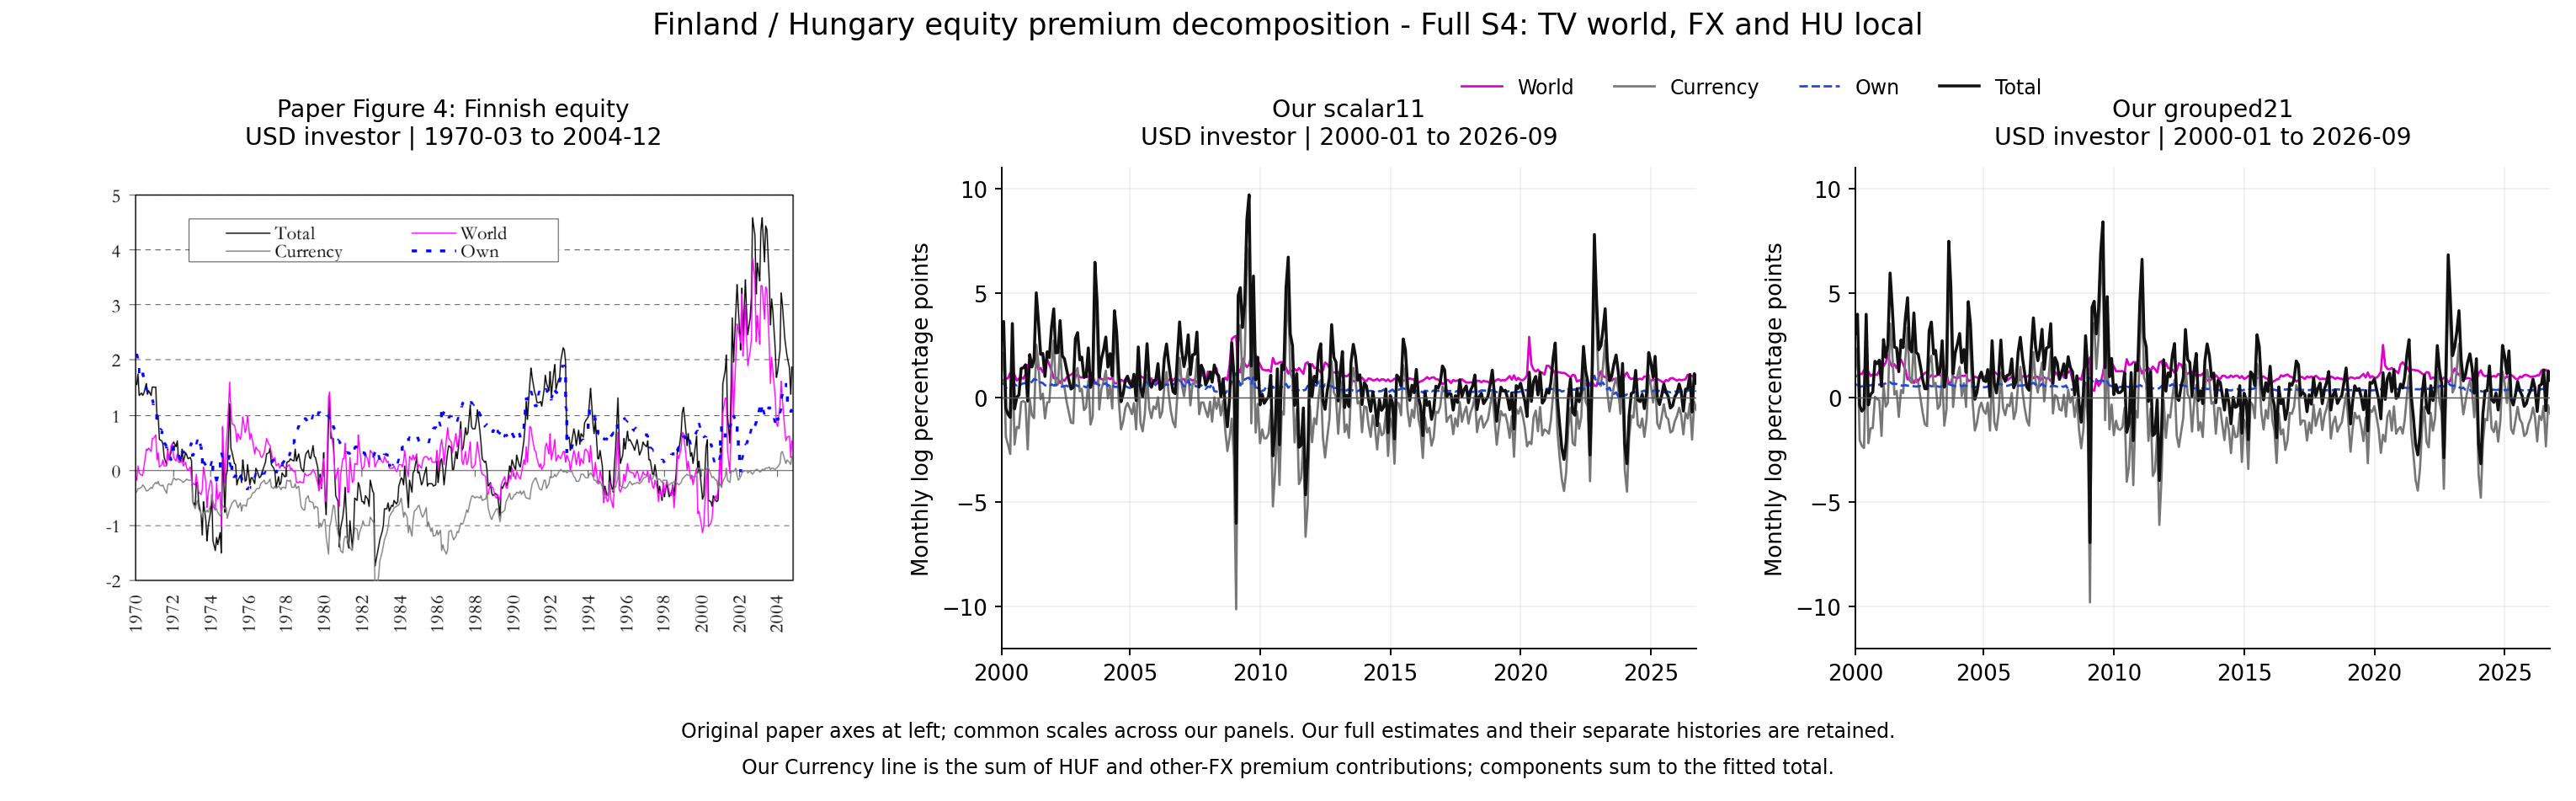

In [3]:
def bounds(values,step):
    lo,hi=float(np.min(values)),float(np.max(values));pad=.04*(hi-lo)
    return np.floor((lo-pad)/step)*step,np.ceil((hi+pad)/step)*step
limits={2:bounds(np.r_[[-.4,.2],np.concatenate([c["prices"][["World","HUF FX","Other FX","HU local"]].to_numpy().ravel() for c in cases.values()])],.1)}
for fig_number,asset in [(3,"US"),(4,"HU")]:limits[fig_number]=bounds(np.r_[[-2,5],np.concatenate([c["premia"][asset].to_numpy().ravel() for c in cases.values()])],1)
titles={2:"Risk-price paths",3:"US equity premium decomposition",4:"Finland / Hungary equity premium decomposition"}
files=[]
for spec in ROOTS:
    for currency in currencies:
        for number in [2,3,4]:
            fig,axes=plt.subplots(1,3,figsize=(18,5.6),gridspec_kw={"width_ratios":[1.12,1,1]})
            axes[0].imshow(source_images[number]);axes[0].axis("off")
            source_asset="World / Finland" if number==2 else "US equity" if number==3 else "Finnish equity"
            axes[0].set_title(f"Paper Figure {number}: {source_asset}\nUSD investor | 1970-03 to 2004-12",fontsize=12,pad=12)
            for ax,model in zip(axes[1:],models):
                c=cases[(spec,currency,model)]
                if number==2:
                    other="EUR FX" if currency=="USD" else "USD FX"
                    for name,label,color in [("World","World","#111111"),("HUF FX","HUF FX","#d82424"),("Other FX",other,"#ba6900"),("HU local","Local, Hungary","#2048d8")]:
                        ax.plot(dates,c["prices"][name],label=label,color=color,lw=1.25)
                    ax.set_ylabel("Risk-price coefficient");legend="lower left"
                else:
                    p=c["premia"]["US" if number==3 else "HU"]
                    currency_color="#2435e8" if number==3 else "#777777";local_color="#9b111e" if number==3 else "#2048d8"
                    for name,color,style in [("World","#df00cb","-"),("Currency",currency_color,"-"),("Own",local_color,"--"),("Total","#111111","-")]:ax.plot(dates,p[name],label=name,color=color,ls=style,lw=1.15 if name!="Total" else 1.5)
                    ax.set_ylabel("Monthly log percentage points");legend="upper right" if number==3 else "upper left"
                ax.set_ylim(*limits[number]);ax.set_xlim(dates[0],dates[-1]);ax.axhline(0,color="#555555",lw=.6)
                ax.set_xticks([dates[0]]+[pd.Timestamp(f"{year}-01-01") for year in [2005,2010,2015,2020,2025]]);ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
                ax.set_title(f"Our {model}\n{currency} investor | 2000-01 to 2026-09",fontsize=12,pad=12)
                
            handles,labels=axes[1].get_legend_handles_labels()
            fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.68,.925),ncol=4,fontsize=10,frameon=False)
            fig.suptitle(f"{titles[number]} - {spec_labels[spec]}",fontsize=15,y=.985)
            fig.subplots_adjust(left=.025,right=.99,bottom=.19,top=.79,wspace=.22)
            note="Original paper axes at left; common scales across our panels. Our full estimates and their separate histories are retained."
            extra="Our HUF and other-FX prices remain separate; quote/basis differences matter." if number==2 else "Our Currency line is the sum of HUF and other-FX premium contributions; components sum to the fitted total."
            fig.text(.5,.08,note,ha="center",fontsize=10);fig.text(.5,.035,extra,ha="center",fontsize=10)
            name=f"{spec}_{currency}_figure_{number}.png";fig.savefig(OUT/name,dpi=170);plt.close(fig)
            files.append({"specification":spec,"perspective":currency,"figure":number,"file":name,"sha256":hashlib.sha256((OUT/name).read_bytes()).hexdigest()})
for n in [2,3,4]:display(Image(filename=str(OUT/f"{SHOW_SPEC}_{SHOW_PERSPECTIVE}_figure_{n}.png")))

## Save the gallery and plotted data

The gallery switches between full S4 / final FX-only and USD / EUR. The original three charts stay
on the left in every view. This package uses no new Finnish observations or fitted series. Figure
images extracted from the supplied PDF are preserved under `source_figures/`, with the PDF digest
and crop coordinates in `source_manifest.json`; keep those local assets for a later base-kernel run.

In [4]:
gallery="""<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Paper pages 16-17 and our versions</title><style>
body{font:16px/1.5 system-ui,sans-serif;color:#172333;background:#f4f6f8;margin:0}main{max-width:1750px;margin:auto;padding:22px}h1{font-size:27px;margin:0 0 8px}p{max-width:1050px}nav{display:flex;gap:22px;align-items:center;flex-wrap:wrap;background:white;padding:14px 18px;border-radius:8px;position:sticky;top:0;box-shadow:0 2px 8px #0001;z-index:2}select{font:inherit;padding:6px;border:1px solid #abb6c2;border-radius:5px}label{font-weight:600}section{background:white;margin:22px 0;padding:14px;border-radius:8px}h2{font-size:20px;margin:0 0 8px}img{width:100%;height:auto;display:block}.muted{font-size:14px;color:#52606e}a{color:#175e9d}</style>
<main><h1>Paper pages 16-17 beside our versions</h1><p>Original charts at left; scalar11 and grouped21 estimates at right. Each panel retains its own dates. The original paper axes remain visible; our panels share a scale and retain all extremes.</p>
<nav><label>Our specification <select id="spec"><option value="S4">Full S4 - structural match</option><option value="FX">Final FX-only branch</option></select></label><label>Our investor <select id="currency"><option>USD</option><option>EUR</option></select></label></nav>
<p id="scope" class="muted"></p>
<section><h2>Figure 2 - Risk-price paths</h2><img id="f2" src="S4_USD_figure_2.png" alt="Paper risk prices beside our scalar and grouped results"><p class="muted">Our two FX prices are shown separately. Their quotes/basis differ from the paper's single currency factor.</p></section>
<section><h2>Figure 3 - US premium decomposition</h2><img id="f3" src="S4_USD_figure_3.png" alt="Paper US premiums beside our two US decompositions"></section>
<section><h2>Figure 4 - Finnish versus Hungarian premium decomposition</h2><img id="f4" src="S4_USD_figure_4.png" alt="Paper Finnish premiums beside our two Hungarian decompositions"><p class="muted">Currency combines our two FX contributions. All components sum to the fitted conditional mean; these are in-sample fitted quantities.</p></section>
<p class="muted">Source: Antell and Vaihekoski, supplied April 2005 draft, printed pp. 16-17 (PDF pp. 18-19). Our data: frozen 2026-11-13 snapshot, 2000-01 through 2026-09, corrected FX means and zero equity alphas. No new fitting, smoothing or fetching.</p>
<script>const spec=document.getElementById('spec'),currency=document.getElementById('currency');function update(){for(const n of [2,3,4])document.getElementById('f'+n).src=spec.value+'_'+currency.value+'_figure_'+n+'.png';document.getElementById('scope').textContent=(spec.value==='S4'?'Full S4 allows world, FX and Hungarian local risk prices to vary; it matches the broad structure of the paper.':'Final FX-only imposes constant world and local risk prices; flat lines reflect those restrictions.')+(currency.value==='EUR'?' The paper remains a USD-investor reference in this EUR view.':' The paper and our panels use the USD-investor perspective.');}spec.addEventListener('change',update);currency.addEventListener('change',update);update();</script></main></html>"""
(OUT/"comparison_gallery.html").write_text(gallery)
audit.to_csv(OUT/"plot_audit.csv",index=False)
manifest={"paper":source_manifest,"source_dataset_sha256":lock["dataset_sha256"],"used_input_sha256":used,"first":"2000-01","last":"2026-09","months":321,"specifications":spec_labels,"covariance_models":models,"perspectives":currencies,
    "source_note":"Authentic raster excerpts; original axes retained, no digitized Finnish numerical series","currency_premia":"sum of two FX contributions; prices kept separate","our_y_limits":limits,"figures":files,"python":sys.executable,"packages":{p:importlib.metadata.version(p) for p in ["numpy","pandas","matplotlib"]}}
(OUT/"comparison_manifest.json").write_text(json.dumps(manifest,indent=2)+"\n")
display(Markdown(f"Gallery: `{(OUT/'comparison_gallery.html').relative_to(ROOT)}`. Change SHOW_SPEC / SHOW_PERSPECTIVE above to display a different three-figure set in this notebook."))

Gallery: `output/17_paper_chart_comparison/fixed_2026-11-13/comparison_gallery.html`. Change SHOW_SPEC / SHOW_PERSPECTIVE above to display a different three-figure set in this notebook.